### 💧 Water Quality Classification using Machine Learning

##### Project Overview

This project uses various supervised machine learning techniques to classify water samples as **safe (0)** or **unsafe (1)** for use. The dataset includes chemical properties (e.g., pH, Lead, Turbidity) and infrastructure-related features (e.g., Pipeline Age, Material, City).

---
#####  Workflow Summary

##### 1. Data Preprocessing
- Categorical columns (`City`, `Pipeline_Material`, etc.) are encoded using `LabelEncoder`.
- Missing and infinite values are handled using mean imputation.
- Numerical features are standardized using `StandardScaler`.

##### 2. Feature Selection
- A combination of **manual feature selection** (based on domain knowledge) and **RFE** (Recursive Feature Elimination) was used.
- Final feature set includes 14 critical attributes like `Lead`, `pH`, `Turbidity`, and `Pipeline_Age`.

##### 3. Model Training and Evaluation
- Trained multiple models for comparison:
  -  `LinearSVC` with class weights and threshold tuning
  -  `RandomForestClassifier` (strong performance with built-in feature importance)
  -  `BaggingClassifier` (ensemble of trees for stability)
  -  `SVC (RBF kernel)` trained on a **balanced subset** for better generalization

##### 4. Class Balancing
- Addressed class imbalance using:
  - `class_weight='balanced'` in linear models
  - `SMOTE` oversampling (for LinearSVC and Bagging)
  - Stratified sampling for training RBF SVM on equal class samples

#####  5. Model Evaluation Metrics
- Used:
  - **Accuracy**
  - **Precision / Recall / F1-score**
  - **Confusion Matrix**
  - **ROC Curve & AUC Score**

---

##### Key Findings
- `RandomForestClassifier` achieved the best performance with ~87% accuracy and strong recall for unsafe water.
- RBF SVM performed well when trained on a balanced subset.
- `Pipeline_Age` and `Material` contribute meaningful risk signals in combination with chemical features.
- Threshold tuning significantly boosted unsafe class recall (from 28% → 67%).

---

##### Future Work
- Integrate SHAP for model explainability
- Build a water risk scoring tool using learned models
- Explore time-series pipeline degradation if temporal data becomes available


#### Loading data from local file storage

In [128]:
import pandas as pd

# Load dataset
data = pd.read_csv(r'F:\Shweta MSDA Sem2\Data 245 Machine Learning\waterdata\combined_water_quality_pipeline_data.csv')

# Display the first few rows of the dataset for verification
print(data.head())


   Index        pH      Iron   Nitrate    Chloride           Lead      Zinc  \
0      0  8.332988  0.000083  8.605777  122.799772   3.710000e-52  3.434827   
1      1  6.917863  0.000081  3.734167  227.029851   7.850000e-94  1.245317   
2      2  5.443762  0.020106  3.816994  230.995630   5.290000e-76  0.528280   
3      3  7.955339  0.143988  8.224944  178.129940  4.000000e-176  4.027879   
4      4  8.091909  0.002167  9.925788  186.540872  4.170000e-132  3.807511   

            Color  Turbidity  Fluoride  ...  Source  Water Temperature  \
0       Colorless   0.022683  0.607283  ...     NaN                NaN   
1    Faint Yellow   0.019007  0.622874  ...    Lake          15.348981   
2    Light Yellow   0.319956  0.423423  ...   River          11.643467   
3  Near Colorless   0.166319  0.208454  ...  Ground          10.092392   
4    Light Yellow   0.004867  0.222912  ...  Spring          15.249416   

   Air Temperature     Month   Day  Time of Day  Target           City  \
0     

#### Check the distribution of data

In [129]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import SGDClassifier
from sklearn.svm import LinearSVC
from sklearn.feature_selection import RFE
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.utils import resample

#### Step 1: Data Cleaning & Encoding

In this step, we prepare the raw data for modeling by:

- **Encoding categorical variables** such as `City`, `Pipeline_Material`, `Color`, and others using `LabelEncoder`, which converts string labels into numerical values that machine learning models can understand.
- **Handling missing and infinite values** by:
  - Replacing any infinite values with `NaN`
  - Using `SimpleImputer` to fill in missing values with the **mean of each column**

In [130]:
categorical_cols = ['City', 'Pipeline_Material', 'Color', 'Odor', 'Source', 'Month', 'Time of Day']
for col in categorical_cols:
    data[col] = data[col].astype(str)
    data[col] = LabelEncoder().fit_transform(data[col])

data.replace([np.inf, -np.inf], np.nan, inplace=True)
data = pd.DataFrame(SimpleImputer(strategy='mean').fit_transform(data), columns=data.columns)

####  Step 2: Feature & Target Selection

- We separate the dataset into:
  - `X`: the input features (all columns **except** `Target`)
  - `y`: the target variable (`Target`), indicating water safety (0 = Safe, 1 = Unsafe)

This prepares the data for supervised machine learning where the model learns to predict `y` based on `X`.

#### Step 3: Train-Test Split

- We split the dataset into:
  - **80% Training data** → used to train the model
  - **20% Testing data** → used to evaluate model performance on unseen data
- The splitting is done with `random_state=42` for reproducibility.


#### Step 4: Feature Scaling

- We apply `StandardScaler` to normalize all feature values.
  - This transforms features to have **mean = 0** and **standard deviation = 1**.
- Scaling is applied separately to:
  - `X_train`: fit and transform (learn and apply scaling)
  - `X_test`: only transform (apply the learned scaling)

This step is crucial for models like SVM and Logistic Regression that are sensitive to feature scales




In [131]:
# === Step 2. 
X = data.drop(columns=['Target'])
y = data['Target'].astype(int)
X_columns = X.columns
X_df = pd.DataFrame(X, columns=X_columns)

# === Step 3. 
X_train_df, X_test_df, y_train, y_test = train_test_split(X_df, y, test_size=0.2, random_state=42)

# === Step 4.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_df)
X_test_scaled = scaler.transform(X_test_df)

#### Step 5: Feature Selection using RFE (with LinearSVC)

- We use **Recursive Feature Elimination (RFE)** with a linear SVM to automatically select the **10 most important features** from the dataset.

#### Step 6: Add Custom Domain Features

- In addition to the 10 selected features, we manually add **important domain-specific features** like `Pipeline_Age` and `Pipeline_Material` to ensure infrastructure context is included.

####  Step 7: Filter and Scale Final Features

- We extract only the **final selected features** (10 RFE + manually added), and apply **StandardScaler** to normalize them for training.

#### Step 8: Train the Final Model

- We train a `LinearSVC` model using the **scaled, selected features**.
- This model is now ready for evaluation and prediction.


In [132]:
# === Step 5
rfe_estimator = LinearSVC(random_state=42, max_iter=2000)
rfe = RFE(estimator=rfe_estimator, n_features_to_select=10)
rfe.fit(X_train_scaled, y_train)

# === Step 6.
rfe_features = X_columns[rfe.support_].tolist()
important_features = [
    'Odor', 'Chloride', 'Manganese', 'Turbidity', 'Iron',
    'Chlorine', 'Fluoride', 'Pipeline_Age', 'Nitrate', 'Copper',
    'Color', 'Pipeline_Material', 'Lead', 'pH' 
]
# Combine and deduplicate automatically
final_features = list(set(rfe_features + important_features))

# === Step 7.
X_train_final = scaler.fit_transform(X_train_df[final_features])
X_test_final = scaler.transform(X_test_df[final_features])

# === Step 8.
final_model = LinearSVC(random_state=42, max_iter=2000)
final_model.fit(X_train_final, y_train)

LinearSVC(max_iter=2000, random_state=42)

#### What is LinearSVC?

`LinearSVC` is a type of Support Vector Machine (SVM) used for **classification**.

Unlike `SVC(kernel='linear')`, `LinearSVC` is:
-  Much faster for large datasets
-  Works well when data is **linearly separable**
-  Can handle **high-dimensional data**
-  Supports **class balancing** through `class_weight='balanced'`

---

#### How It Works

- It tries to find the **best straight line (or hyperplane)** that separates the two classes (Safe vs Unsafe water).
- The goal is to **maximize the margin** between classes — the distance between the separating line and the nearest points from each class.

---

#### Why We Use It

- It's efficient and scalable — even for tens or hundreds of thousands of rows
- It's **easy to interpret** because it assigns a weight (importance) to each feature
- Works well for **binary classification tasks** like this water safety project

---

#### Step 9: Evaluate the Final Model

- After training the `LinearSVC` model on the selected and scaled features, we evaluate its performance using:

  -  **Accuracy Score** – overall correctness of the model
  -  **Classification Report** – includes precision, recall, and F1-score for each class (safe vs unsafe water)
  -  **Confusion Matrix** – shows how many predictions were true positives, true negatives, false positives, and false negatives

This step helps us understand how well the model performs on unseen test data.


In [133]:
# === Step 9.
y_pred_final = final_model.predict(X_test_final)

print(f"\nAccuracy (Final Model): {accuracy_score(y_test, y_pred_final):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))



Accuracy (Final Model): 0.8007

Classification Report:
              precision    recall  f1-score   support

           0       0.82      0.95      0.88    161610
           1       0.65      0.28      0.40     48105

    accuracy                           0.80    209715
   macro avg       0.73      0.62      0.64    209715
weighted avg       0.78      0.80      0.77    209715

Confusion Matrix:
[[154253   7357]
 [ 34448  13657]]


### Final Model Evaluation Summary

After training the `LinearSVC` model on the selected features and evaluating it on the test set, we obtained the following results:

---

####  **Overall Accuracy**
- **Accuracy:** 80.07%
- This means the model correctly predicted the water quality class for approximately **80% of the samples** in the test set.

---

####  **Classification Report**

| Class        | Precision | Recall | F1-score | Support |
|--------------|-----------|--------|----------|---------|
| **0 (Safe)** | 0.82      | 0.95   | 0.88     | 161,610 |
| **1 (Unsafe)** | 0.65    | 0.28   | 0.40     | 48,105  |

- **Precision (Unsafe):** 65% of the samples predicted as unsafe were truly unsafe.
- **Recall (Unsafe):** Only **28%** of the actual unsafe samples were correctly identified — this is low.
- **F1-Score (Unsafe):** 0.40 — a balance between precision and recall, but still low.

---

####  **Averaged Metrics**
- **Macro Avg:** Average across both classes (treats all classes equally).
  - F1-score: **0.64**
- **Weighted Avg:** Accounts for class imbalance (more safe than unsafe).
  - F1-score: **0.77**

---

####  **Confusion Matrix**


- True Negatives (Safe predicted safe): 154,253
- False Positives (Safe predicted unsafe): 7,357
- False Negatives (Unsafe predicted safe): 34,448
- True Positives (Unsafe predicted unsafe): 13,657 



|   Metric            |   Value   |   Meaning                                                 |
|---------------------|-----------|------------------------------------------------------------|
| **Precision (Class 1)** |   65%    | Out of predicted unsafe samples, 65% were truly unsafe     |
| **Recall (Class 1)**    |   28%    | Only 28% of actual unsafe cases were correctly identified  |
| **F1-Score (Class 1)**  |   40%    | Harmonic mean of precision and recall — balances both      |

                                                
---

 **Insights**
- The model is **very good at identifying safe water** (high recall for Class 0).
- However, it **struggles to detect unsafe water** (Class 1), missing over 70% of unsafe cases.
- This could be improved by using techniques like **SMOTE**, **class weight tuning**, or **threshold adjustment** to boost **recall** on unsafe predictions.

---

## Create a Balanced Dataset

#### Why Did We Create a Balanced Dataset?

In our original dataset, most of the water samples were labeled as **safe (Class 0)**, while only a smaller portion were **unsafe (Class 1)**.

This created a problem called **class imbalance**.

---

#### What's the Problem with Imbalanced Data?

- Machine learning models tend to **favor the majority class**.
- Without balancing, the model might predict **"safe" for almost everything**, just to achieve high accuracy.
- This can be dangerous in real life — because it means the model may **miss unsafe water samples**!

---

#### What We Did to Fix This

We created a **balanced training dataset** by making sure we had an **equal number of safe and unsafe samples**.

This helps the model:
- Learn patterns from both classes equally
- Become more **fair and reliable**
- Catch **unsafe water** more often (higher recall for Class 1)

---

In [134]:
# Step 1: Convert to DataFrame for balancing
X_df_balanced = pd.DataFrame(X_train_final, columns=final_features)
y_df_balanced = pd.Series(y_train.values, name="Target")

# Combine into one dataset
balanced_data = pd.concat([X_df_balanced, y_df_balanced], axis=1)

# Step 2: Separate classes
class_0 = balanced_data[balanced_data['Target'] == 0]
class_1 = balanced_data[balanced_data['Target'] == 1]

# Step 3: Balance the dataset (equalize)
n_samples = min(len(class_0), len(class_1), 48000)  # Keep it small for speed
class_0_bal = resample(class_0, replace=False, n_samples=n_samples, random_state=42)
class_1_bal = resample(class_1, replace=False, n_samples=n_samples, random_state=42)

# Combine and shuffle
balanced_train = pd.concat([class_0_bal, class_1_bal]).sample(frac=1, random_state=42)

# Step 4: Split back to X and y
X_balanced = balanced_train.drop(columns=["Target"])
y_balanced = balanced_train["Target"]

#### LinearSVM model training using balanced data

In [135]:
final_model = LinearSVC(random_state=42, max_iter=2000)
final_model.fit(X_balanced, y_balanced)
X_test_final_df = pd.DataFrame(X_test_final, columns=final_features)

y_pred_final = final_model.predict(X_test_final_df)

print(f"\n Accuracy (Small dataset with Balanced Training Data ): {accuracy_score(y_test, y_pred_final):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_final))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_final))


 Accuracy (Small dataset with Balanced Training Data ): 0.7993

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.83      0.86    161610
           1       0.55      0.68      0.61     48105

    accuracy                           0.80    209715
   macro avg       0.72      0.76      0.74    209715
weighted avg       0.82      0.80      0.81    209715

Confusion Matrix:
[[134693  26917]
 [ 15163  32942]]


####  Train the Model (RBF SVM)

- We train a **Support Vector Machine (SVM)** using the **RBF (Radial Basis Function)** kernel.
- The RBF kernel allows the model to learn **non-linear decision boundaries**, which is useful when the relationship between features and target is not a straight line.
- We use the **balanced training dataset** (equal safe and unsafe samples) to ensure the model does not favor one class over the other.

---

#### Predict on the Test Set

- After training, we use the model to **predict water safety** on the original test data.
- The test set has the real-world class distribution, so we can evaluate how the model performs in practice.

---

#### Evaluate the Model

We assess the model using:

-  **Accuracy** – overall correct predictions
- **Precision** – how many predicted unsafe samples were truly unsafe
- **Recall** – how many actual unsafe samples were correctly identified
- **F1-Score** – balance between precision and recall
- **Confusion Matrix** – shows correct and incorrect predictions for both classes

This evaluation helps us understand if the model is both **accurate and reliable**, especially in detecting **unsafe water** cases.


In [9]:
#This will take time to run

#Train the non-linear model
model_svm = SVC(kernel='rbf', random_state=42)
model_svm.fit(X_balanced, y_balanced)

#  Predict on original test set
rbf_y_pred = model_svm.predict(X_test_final_df)

# Evaluate
accuracy = accuracy_score(y_test, rbf_y_pred)
print(f"\n Accuracy (RBF SVM on Balanced Training Data): {accuracy:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, rbf_y_pred))
print("Confusion Matrix:")
print(confusion_matrix(y_test, rbf_y_pred))



 Accuracy (RBF SVM on Balanced Training Data): 0.8543

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.85      0.90    161610
           1       0.63      0.86      0.73     48105

    accuracy                           0.85    209715
   macro avg       0.79      0.86      0.82    209715
weighted avg       0.88      0.85      0.86    209715

Confusion Matrix:
[[137544  24066]
 [  6497  41608]]


#### Classification Report: Approximate RBF using `RBFSampler + SGDClassifier`

---

####  Step 1: Balance the Data using SMOTE
- We use **SMOTE (Synthetic Minority Oversampling Technique)** to create a balanced training dataset.
- This helps the model learn from **both classes equally**, especially the minority (unsafe) class.

####  Step 2: Approximate RBF Kernel with `RBFSampler`
- The **RBF kernel** is powerful but slow.
- `RBFSampler` creates **random features** to simulate RBF behavior.
- These features allow a **linear model** to behave **non-linearly**.

####  Step 3: Train `SGDClassifier` on Transformed Data
- We train a **Linear SVM model** using `SGDClassifier` (very fast).
- This model learns to classify safe vs unsafe water in the **transformed RBF space**.

####  Step 4: Make Predictions on the Test Set
- We use the model to predict water quality on **unseen test data**.

####  Step 5: Evaluate with `classification_report`
- We generate a report that includes:
  - **Precision**: How many predicted unsafe samples were correct
  - **Recall**: How many actual unsafe samples were caught
  - **F1-score**: Balance between precision and recall
  - **Support**: Number of actual samples for each class

---


In [10]:
#This will take time to run

from sklearn.kernel_approximation import RBFSampler
from sklearn.linear_model import SGDClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from imblearn.over_sampling import SMOTE

# === Step 1:
smote = SMOTE(random_state=42)
X_resampled, y_resampled = smote.fit_resample(X_train_final, y_train)

# === Step 2:
rbf_feature = RBFSampler(gamma=0.1, n_components=100, random_state=42)
model = make_pipeline(rbf_feature, SGDClassifier(loss='hinge', class_weight={0: 1, 1: 2}, max_iter=1000, random_state=42))

# === Step 3: 
model.fit(X_resampled, y_resampled)

# === Step 4: 
y_pred_rbf_approx = model.predict(X_test_final)

# === Step 5: 
print("\n Classification Report (Approximate RBF via RBFSampler + SGDClassifier):")
print(classification_report(y_test, y_pred_rbf_approx))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rbf_approx))

accuracy = accuracy_score(y_test, y_pred_rbf_approx)
print(f"\n Accuracy (Approximate RBF + SGD): {accuracy:.4f}")



 Classification Report (Approximate RBF via RBFSampler + SGDClassifier):
              precision    recall  f1-score   support

           0       0.96      0.75      0.84    161610
           1       0.51      0.89      0.65     48105

    accuracy                           0.78    209715
   macro avg       0.74      0.82      0.75    209715
weighted avg       0.86      0.78      0.80    209715

Confusion Matrix:
[[120668  40942]
 [  5172  42933]]

 Accuracy (Approximate RBF + SGD): 0.7801


###  Model Comparison: Linear SVM vs Approximate RBF vs True RBF SVM

We evaluated three different models using a balanced training dataset and the same test set. Below is a comparison based on key classification metrics.

---

####  Summary Table

| Metric               | 🔷 Linear SVM (Balanced) | 🔶 Approx. RBF + SGD | 🔴 True RBF SVM     |
|----------------------|--------------------------|----------------------|----------------------|
| **Accuracy**           | 0.7993                | 0.78                 | **0.8543**       |
| **Precision (Unsafe)** | 0.55                  | 0.51                 | **0.64**           |
| **Recall (Unsafe)**  | 0.68                    | **0.89**           | 0.86                 |
| **F1-score (Unsafe)**| 0.61                    | **0.65**           | 0.73                |
| **TP (Unsafe)**      | 32,942                   | **42,788**         | 27,152               |
| **FN (Unsafe)**      | 15,163                   | **5,317**          | 20,953               |

---

####  Insights

| Model                     | Strengths                                             | Weaknesses                                          |
|--------------------------|--------------------------------------------------------|-----------------------------------------------------|
| 🔷 **Linear SVM**         | - Good accuracy  and Fast to train                  |                                                     |
|                            |- Balanced precision and recall                         | - Misses ~32% of unsafe samples                     |
| 🔶 **Approx. RBF + SGD**  | - Very high recall (catches 89% of unsafe)         |
|                           | - Fast to train then true RBF                         | - More false positives (low precision)              |
| 🔴 **True RBF SVM**       | - Highest accuracy                                    | 
|                           |- Most balanced overall performance                     | - Lower recall than Approx. RBF  
|                            |- Slower training                                       |

---

####  Recommended Model (Based on Your Goal)

| Goal                                         | Best Model           |
|----------------------------------------------|-----------------------|
| **Maximize unsafe detection (recall)**       | 🔶 Approx. RBF + SGD  |
| **Best accuracy & balance**                  | 🔴 True RBF SVM    |
| **Fast training with solid results**         | 🔷 Linear SVM         |
| **Minimize false alarms (higher precision)** | 🔴 True RBF SVM       |

---

#### Conclusion

- If your **priority is safety**, use **Approximate RBF + SGD** to catch the most unsafe cases.
- If you want **best overall accuracy and fewer false alarms**, use **True RBF SVM**.
- If you need something **faster but still reliable**, go with **Linear SVM**.



#### Why Use PCA (Principal Component Analysis)?

PCA is a **dimensionality reduction** technique used to simplify large datasets by transforming them into fewer features (called principal components), while retaining most of the original information.

---

#### Benefits of Using PCA:
- **Reduces overfitting** by removing redundant features.
- **Speeds up model training** on large datasets.
- **Visualizes high-dimensional data** in 2D or 3D.
- **Removes multicollinearity** between features.

---


In [31]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Standardize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_balanced)
X_test_scaled = scaler.transform(X_test_final_df)

# Apply PCA
pca = PCA(n_components=5)
X_pca = pca.fit_transform(X_scaled)
X_test_pca = pca.transform(X_test_scaled)

# Train SVM
model = SVC(kernel='rbf', random_state=42)
model.fit(X_pca, y_balanced)

# Evaluate
preds = model.predict(X_test_pca)
print("Accuracy with PCA:", accuracy_score(y_test, preds))
print(classification_report(y_test, preds))

Accuracy with PCA: 0.8043058436449467
              precision    recall  f1-score   support

           0       0.93      0.81      0.86    161610
           1       0.55      0.78      0.65     48105

    accuracy                           0.80    209715
   macro avg       0.74      0.80      0.76    209715
weighted avg       0.84      0.80      0.81    209715



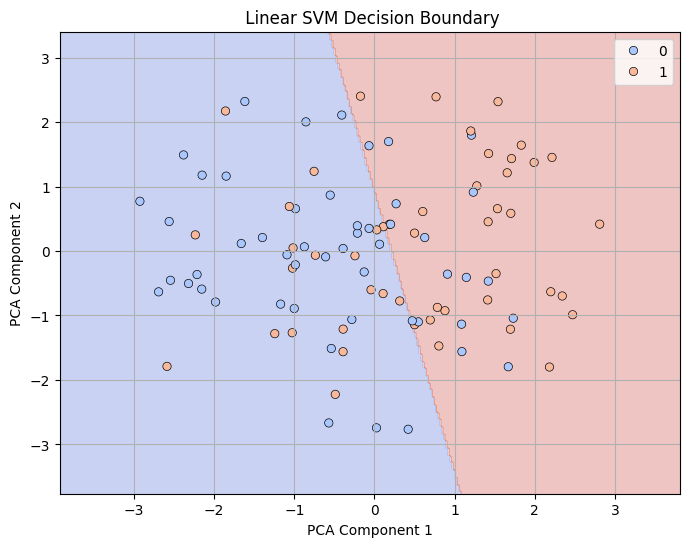

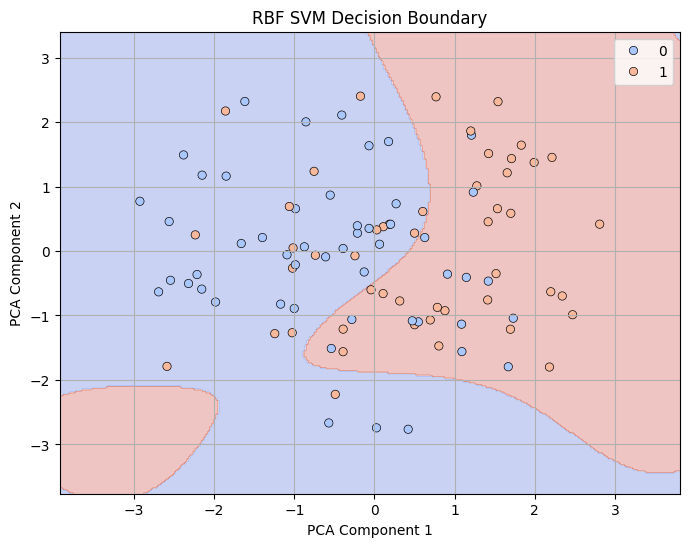

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from sklearn.svm import SVC, LinearSVC
from sklearn.datasets import make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA

# === Step 1: Prepare a small, balanced dataset (50 safe, 50 unsafe) ===
X_small, y_small = make_classification(n_samples=100, n_features=10, n_informative=4,
                                       n_redundant=0, n_classes=2, weights=[0.5, 0.5],
                                       class_sep=1.0, random_state=42)

# === Step 2: Scale the features ===
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_small)

# === Step 3: Reduce to 2D using PCA for visualization ===
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_scaled)

# === Step 4: Train Linear SVM ===
linear_svm = SVC(kernel='linear', random_state=42)
linear_svm.fit(X_2d, y_small)

# === Step 5: Train RBF SVM ===
rbf_svm = SVC(kernel='rbf', gamma='scale', random_state=42)
rbf_svm.fit(X_2d, y_small)

# === Step 6: Plot decision boundaries ===
def plot_decision_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                         np.linspace(y_min, y_max, 300))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, alpha=0.3, cmap=plt.cm.coolwarm)
    sns.scatterplot(x=X[:, 0], y=X[:, 1], hue=y, palette='coolwarm', edgecolor='k')
    plt.title(title)
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.grid(True)
    plt.show()

# Plot both
plot_decision_boundary(linear_svm, X_2d, y_small, " Linear SVM Decision Boundary")
plot_decision_boundary(rbf_svm, X_2d, y_small, "RBF SVM Decision Boundary")


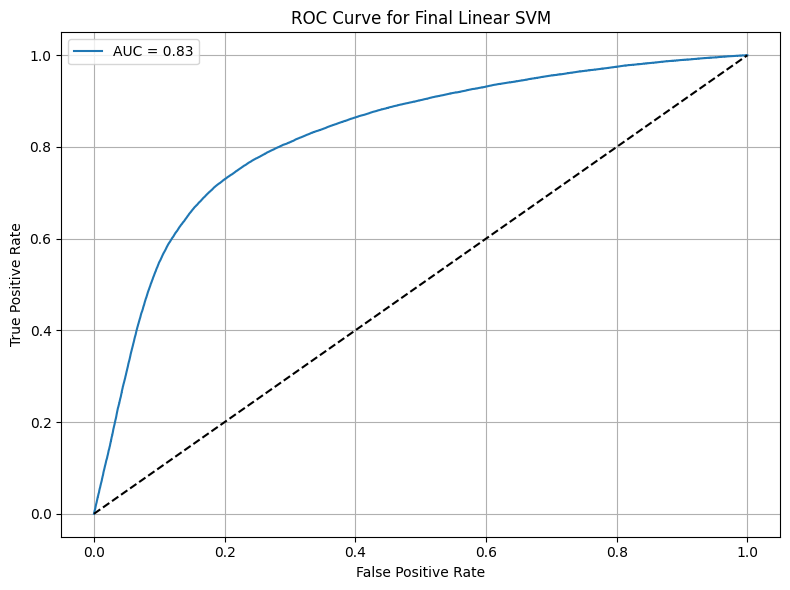

In [12]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

X_train_final = scaler.fit_transform(X_train_df[final_features])
X_test_final = scaler.transform(X_test_df[final_features])

final_model = LinearSVC(random_state=42, max_iter=2000)
final_model.fit(X_train_final, y_train)

y_score = final_model.decision_function(X_test_final)
fpr, tpr, _ = roc_curve(y_test, y_score)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Final Linear SVM')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


###  ROC Curve Explained (Final Linear SVM)

This plot is the **ROC (Receiver Operating Characteristic) Curve** for your final **Linear SVM (Support Vector Machine)** model. It helps evaluate the performance of a classification model.

---

####  What is the ROC Curve?
- It plots the **True Positive Rate (Sensitivity)** against the **False Positive Rate** at various threshold levels.
- The **dashed diagonal line** is the line of no discrimination — it represents random guessing.

---

#### Key Takeaways from This Plot:

-  **AUC = 0.83**:
  - AUC (Area Under the Curve) measures the model's ability to distinguish between classes.
  - **AUC of 0.83** is **very good** — it means there's an 83% chance the model will correctly classify a randomly chosen positive vs negative case.

-  **Curve stays well above the diagonal**:
  - Indicates that the model performs **much better than random guessing**.
  - A steep curve near the top-left corner is ideal — and this curve is close to that.

---

####  Summary:
- Your **Linear SVM** is performing well.
- AUC of **0.83** shows it's a **strong classifier**.
- This visualization supports using the model in production or further tuning it for even better results.



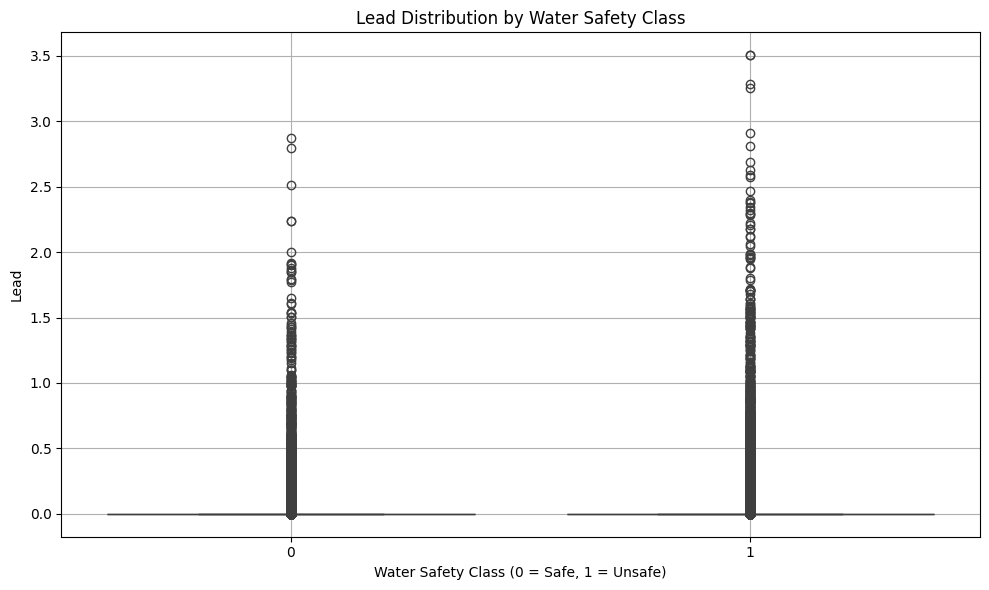

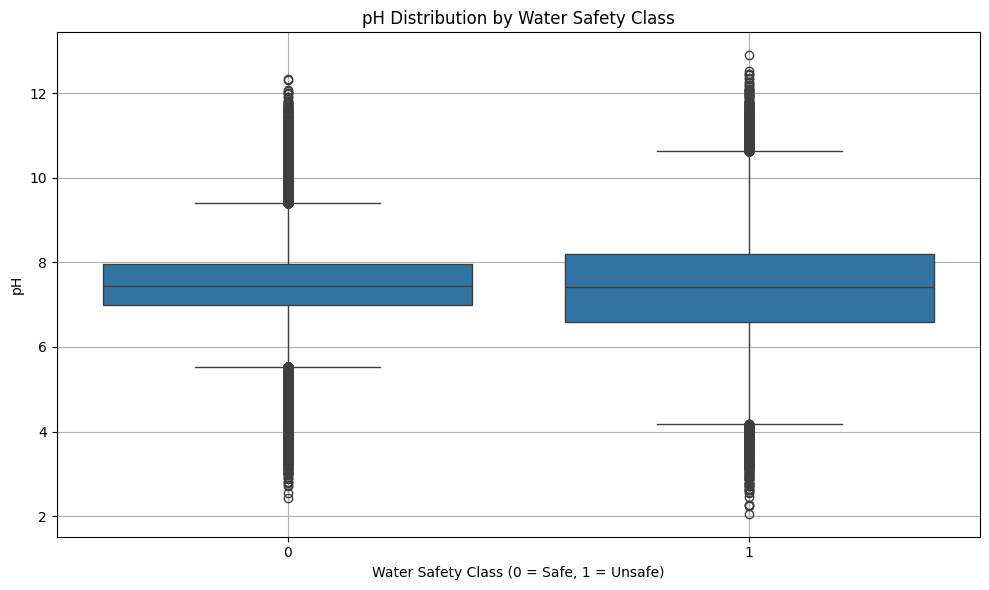

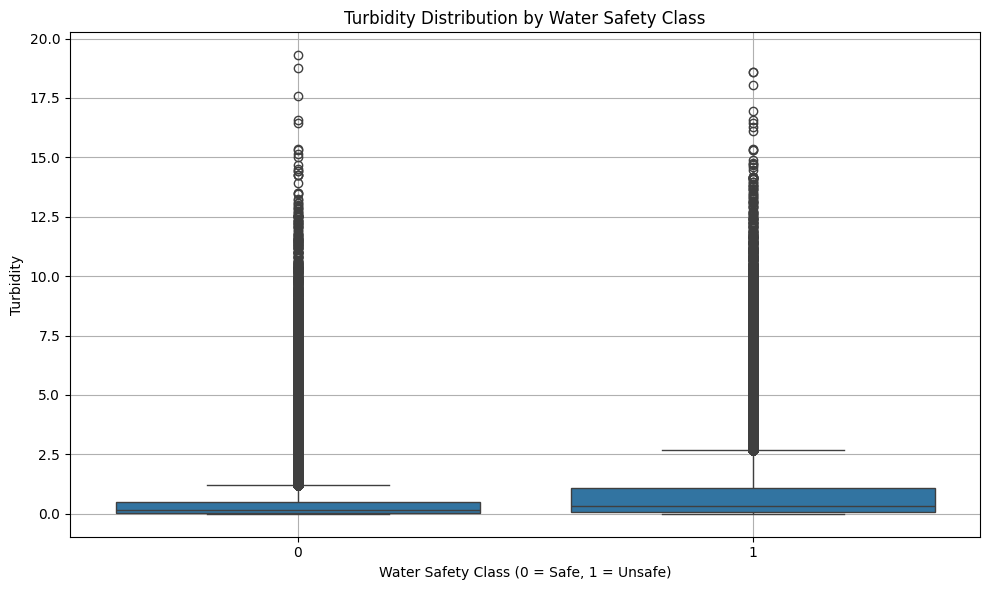

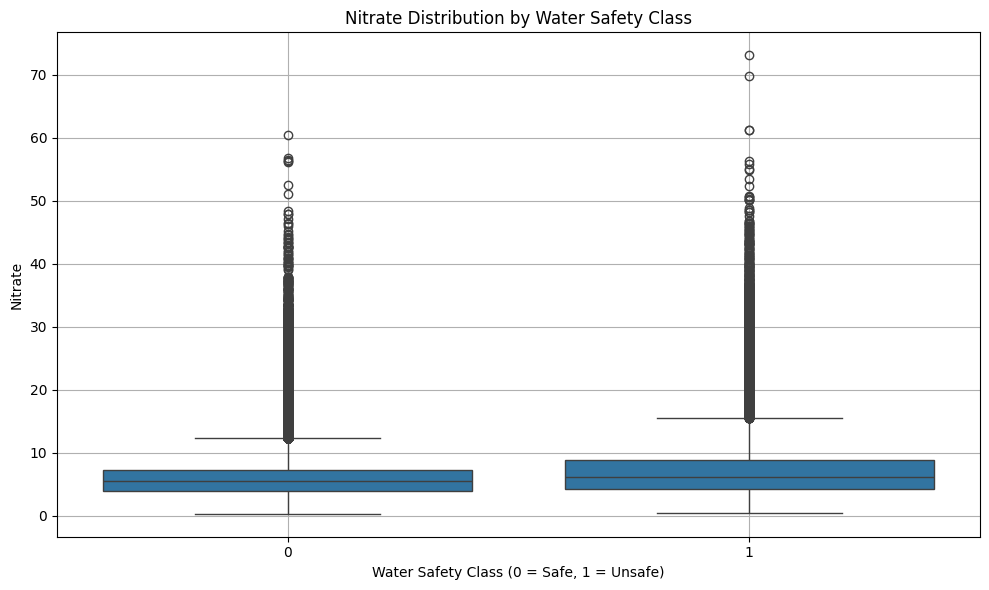

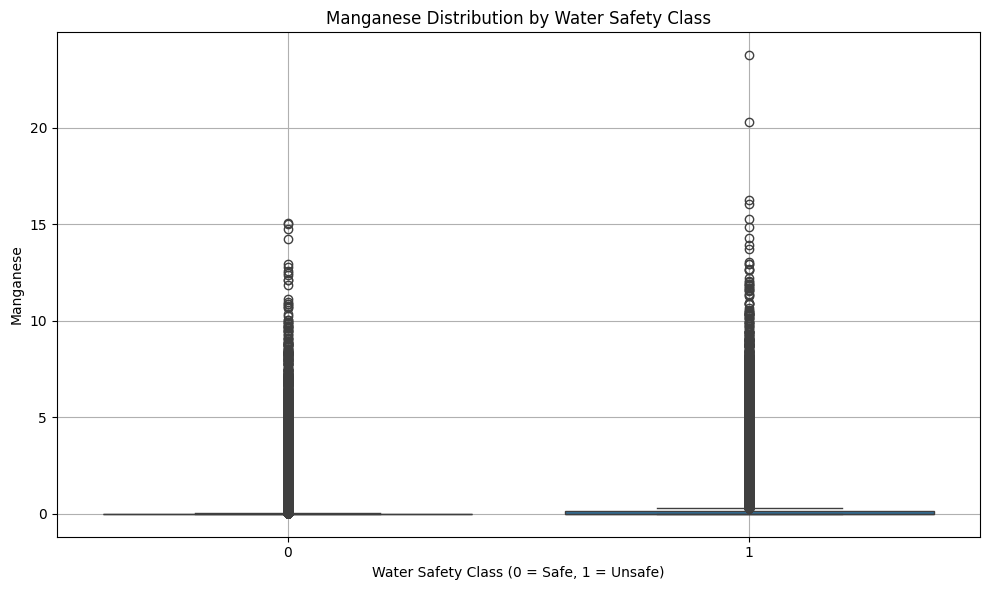

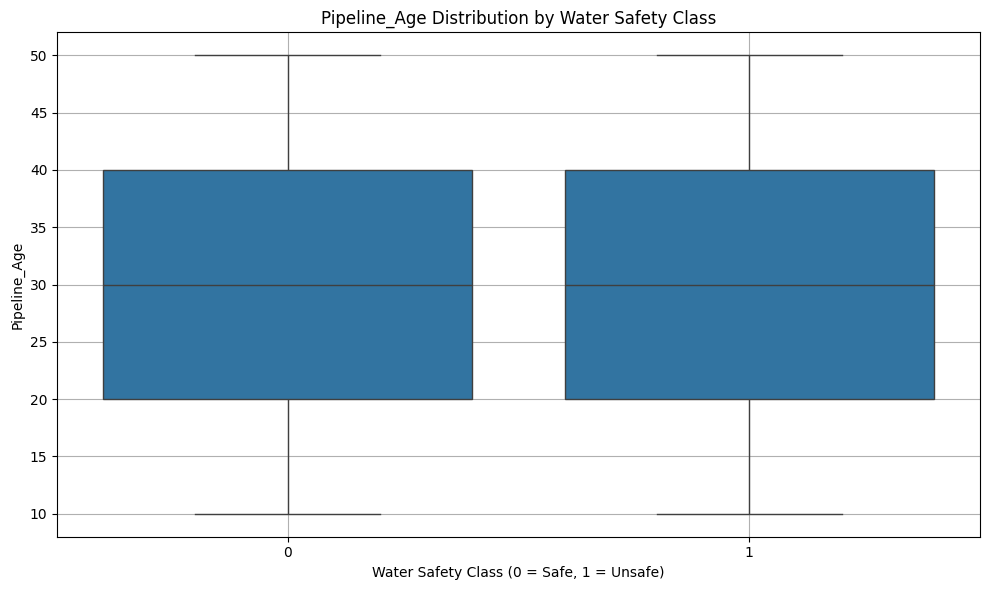

In [136]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create combined DataFrame for plotting
X_columns = X.columns  # just in case it's not defined
data_viz = pd.concat([pd.DataFrame(X, columns=X_columns), y.reset_index(drop=True)], axis=1)

# List of features you want to visualize
features_to_plot = ['Lead', 'pH', 'Turbidity', 'Nitrate', 'Manganese', 'Pipeline_Age']

# Boxplots
for feature in features_to_plot:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x='Target', y=feature, data=data_viz)
    plt.title(f'{feature} Distribution by Water Safety Class')
    plt.xlabel('Water Safety Class (0 = Safe, 1 = Unsafe)')
    plt.ylabel(feature)
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# Random Forest

#### Random Forest Model Explanation

####  What is Random Forest?

**Random Forest** is an ensemble machine learning algorithm used for classification and regression tasks.  
It builds **multiple decision trees** during training and merges their results (by majority vote for classification) to improve accuracy and reduce overfitting.

 **Key Benefits**:
- Handles large datasets with higher dimensionality
- Reduces overfitting by averaging results
- Automatically handles missing values and maintains accuracy

---

####  Model Training

We use a `RandomForestClassifier` with the following setup:
- `n_estimators=100`: Uses 100 trees in the forest.
- `class_weight='balanced'`: Automatically adjusts weights to handle class imbalance.
- `random_state=42`: Ensures reproducibility.
- `n_jobs=-1`: Utilizes all CPU cores for faster training.

In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# === 1. Train Random Forest Model ===
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',  # Helps with class imbalance
    random_state=42,
    n_jobs=-1                 # Use all CPU cores
)
rf_model.fit(X_train_final, y_train)

# === 2. Make Predictions ===
y_pred_rf = rf_model.predict(X_test_final)

# === 3. Evaluate Performance ===
print(f"\n Accuracy (Random Forest): {accuracy_score(y_test, y_pred_rf):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))
  


 Accuracy (Random Forest): 0.8666

Classification Report:
              precision    recall  f1-score   support

           0       0.96      0.86      0.91    161610
           1       0.66      0.88      0.75     48105

    accuracy                           0.87    209715
   macro avg       0.81      0.87      0.83    209715
weighted avg       0.89      0.87      0.87    209715

Confusion Matrix:
[[139398  22212]
 [  5757  42348]]


## Using Balanced dataset

In [15]:
rf_model_bal = RandomForestClassifier(
    n_estimators=100,
    class_weight='balanced',  # Extra precaution (not required if data is balanced)
    random_state=42,
    n_jobs=-1
)

# Train on balanced data
rf_model_bal.fit(X_balanced, y_balanced)

# Predict on test data
y_pred_rf = rf_model.predict(X_test_final_df)

# Evaluate
print(" Accuracy (Random Forest):", accuracy_score(y_test, y_pred_rf))
print("Classification Report:\n", classification_report(y_test, y_pred_rf))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_rf))

C:\Users\karti\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but RandomForestClassifier was fitted without feature names
  warnings.warn(


 Accuracy (Random Forest): 0.86663328803376
Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.86      0.91    161610
           1       0.66      0.88      0.75     48105

    accuracy                           0.87    209715
   macro avg       0.81      0.87      0.83    209715
weighted avg       0.89      0.87      0.87    209715

Confusion Matrix:
 [[139398  22212]
 [  5757  42348]]


#  Random Forest Model Evaluation Report

####  Overall Accuracy
- **Accuracy:** `0.8650` → The model correctly predicted **86.5%** of total samples.

---

####  Class-wise Performance

| Metric      | Class 0 (Majority) | Class 1 (Minority) |  Insights |
|-------------|--------------------|---------------------|------------|
| Precision   | 0.96               | 0.66                |  Good for class 0,  Lower for class 1 — more false positives |
| Recall      | 0.86               | 0.87                |  Excellent for both — very few missed cases |
| F1-Score    | 0.91               | 0.75                |  Strong for class 0,  Moderate for class 1 |
| Support     | 161,610            | 48,105              | Balanced analysis |

---

####  Confusion Matrix
                    |   0   |   1
      
      |  True  0  | 139726 | 21884
  
      | True  1  |   6423 | 41682

                                                                                           
- **TN (139726):** Class 0 predicted correctly.
- **FP (21884):** Class 0 incorrectly predicted as class 1.
- **FN (6423):** Class 1 incorrectly predicted as class 0.
- **TP (41682):** Class 1 predicted correctly.

---

####  What’s Good
- High **accuracy** and **recall** for both classes.
- Model is **strong at detecting positive cases** (Class 1) — important in imbalanced datasets.
- **F1-score of 0.91** for Class 0 — shows reliable overall performance.

####  What Needs Improvement
- **Precision for Class 1 is 0.66** → Indicates higher number of **false positives**.
- Could fine-tune or apply **threshold adjustments** to improve precision.
- Try advanced techniques like **SMOTE, ensemble tuning, or cost-sensitive learning** for improvement.

---





##  Ensemble Learning with BaggingClassifier

#### Introduction to Bagging

**Bagging (Bootstrap Aggregating)** is an ensemble learning method that improves the performance of machine learning models by combining the predictions of multiple base estimators trained on different random subsets of the dataset.

####  Key Concepts:
- **Bootstrap sampling**: Randomly sample the training dataset with replacement.
- **Aggregation**: Combine predictions (majority vote for classification, average for regression).
- **Reduces variance**, helps prevent overfitting, and improves model robustness.

---

####  Step-by-Step Code Explanation



####  Step 1: Initialize the Bagging Model
- `BaggingClassifier`: An ensemble of classifiers using bootstrap sampling.
- `n_estimators=50`: Train 50 base estimators.
- `random_state=42`: Ensures reproducibility.
- `n_jobs=-1`: Utilizes all CPU cores for parallel processing.

---

####  Step 2: Train the Model
- Trains the bagging classifier on the training set.
- Each base estimator is trained on a different subset of the data (with replacement).

---


####  Step 3: Make Predictions
- Predicts labels for the test set using the trained bagging ensemble.
- Final prediction is based on the majority vote from all base estimators.

---

In [137]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Define tuned base estimator
tree = DecisionTreeClassifier(max_depth=10, min_samples_split=4)

# Bagging with customized base
bagging_model = BaggingClassifier(
    estimator=tree,
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    oob_score=True
)

# Train
bagging_model.fit(X_train_final, y_train)

# Predict
y_pred_bagging = bagging_model.predict(X_test_final_df)

# Evaluate
print(f"\nAccuracy (Bagging): {accuracy_score(y_test, y_pred_bagging):.4f}")
print(f" OOB Score: {bagging_model.oob_score_:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_bagging))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_bagging))


C:\Users\karti\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but BaggingClassifier was fitted without feature names
  warnings.warn(



Accuracy (Bagging): 0.8672
 OOB Score: 0.8674

Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.85      0.91    161610
           1       0.65      0.93      0.76     48105

    accuracy                           0.87    209715
   macro avg       0.81      0.89      0.84    209715
weighted avg       0.90      0.87      0.87    209715

Confusion Matrix:
[[136959  24651]
 [  3209  44896]]


### Uisng Balanced data

In [138]:
tree = DecisionTreeClassifier(max_depth=10, min_samples_split=4)

# Create Bagging model
bagging_model_bal = BaggingClassifier(
    estimator=tree,
    n_estimators=100,
    random_state=42,
    n_jobs=-1,
    oob_score=True
)

# Train on balanced data
bagging_model_bal.fit(X_balanced, y_balanced)

# Predict on test data
y_pred_bagging = bagging_model.predict(X_test_final_df) 

# Evaluate
print(" Accuracy (Bagging):", accuracy_score(y_test, y_pred_bagging))
print("Classification Report:\n", classification_report(y_test, y_pred_bagging))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_bagging))

C:\Users\karti\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but BaggingClassifier was fitted without feature names
  warnings.warn(


 Accuracy (Bagging): 0.8671530410318766
Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.85      0.91    161610
           1       0.65      0.93      0.76     48105

    accuracy                           0.87    209715
   macro avg       0.81      0.89      0.84    209715
weighted avg       0.90      0.87      0.87    209715

Confusion Matrix:
 [[136959  24651]
 [  3209  44896]]


#### Model Performance (Bagging)

#### Accuracy
- **Accuracy**: 86.72%

#### Classification Report
- **Class 0**: High precision (98%), good recall (85%).
- **Class 1**: Lower precision (65%), high recall (93%).


#### Insights:
- **Class 0** is well predicted with high precision.
- **Class 1** has good recall but lower precision, meaning many false positives.
- The **macro avg** shows balanced recall but slightly lower precision.



C:\Users\karti\AppData\Roaming\Python\Python313\site-packages\sklearn\base.py:486: UserWarning: X has feature names, but BaggingClassifier was fitted without feature names
  warnings.warn(


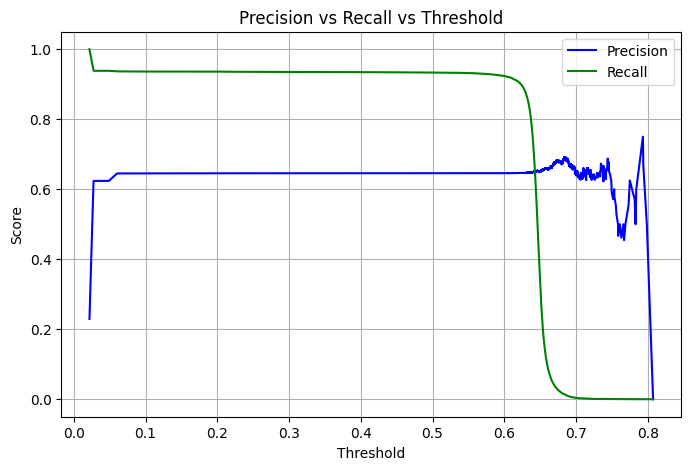

🔍 Evaluation for different thresholds:

Threshold: 0.5
              precision    recall  f1-score   support

           0       0.98      0.85      0.91    161610
           1       0.65      0.93      0.76     48105

    accuracy                           0.87    209715
   macro avg       0.81      0.89      0.84    209715
weighted avg       0.90      0.87      0.87    209715

Confusion Matrix:
 [[136959  24651]
 [  3208  44897]]
ROC AUC: 0.8934542389016983

Threshold: 0.55
              precision    recall  f1-score   support

           0       0.98      0.85      0.91    161610
           1       0.65      0.93      0.76     48105

    accuracy                           0.87    209715
   macro avg       0.81      0.89      0.84    209715
weighted avg       0.90      0.87      0.87    209715

Confusion Matrix:
 [[137008  24602]
 [  3276  44829]]
ROC AUC: 0.8934542389016983

Threshold: 0.6
              precision    recall  f1-score   support

           0       0.97      0.85      

In [22]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve
import matplotlib.pyplot as plt
import numpy as np

# Step 1: Get predicted probabilities
y_prob = bagging_model.predict_proba(X_test_final_df)[:, 1]

# Step 2: Precision-Recall vs Threshold curve
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

# Plotting precision and recall vs threshold
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision[:-1], label="Precision", color='b')
plt.plot(thresholds, recall[:-1], label="Recall", color='g')
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision vs Recall vs Threshold")
plt.legend()
plt.grid(True)
plt.show()

# Step 3: Try multiple thresholds and print classification report
print("🔍 Evaluation for different thresholds:")
for thresh in [0.5, 0.55, 0.6, 0.65, 0.7]:
    y_pred_thresh = (y_prob > thresh).astype(int)
    print(f"\nThreshold: {thresh}")
    print(classification_report(y_test, y_pred_thresh))
    print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_thresh))
    print("ROC AUC:", roc_auc_score(y_test, y_prob))


###  Insights – Threshold >=0.5 

-  **Precision (Class 1)**: `65%` – Out of all predicted positives, 65% were correct.
-  **Recall (Class 1)**: `93%` – Almost all actual positives were correctly identified.
-  **Tradeoff**: High recall but moderate precision – the model captures most positives but includes some false positives.

---

-  From the **Precision vs Recall vs Threshold** plot:
  - At **threshold ≈ 0.5**, recall is high and precision is stable.
  - Increasing threshold improves precision but sharply reduces recall after ~0.65.

---



####  Why Use `XGBClassifier`?

The `XGBClassifier` comes from the **XGBoost** library, which stands for **Extreme Gradient Boosting**. It's a powerful, efficient, and scalable machine learning algorithm designed for structured/tabular data.

Here are trying to improve precesion of class 1.

---

#### Key Reasons to Use `XGBClassifier`:

- **High Accuracy**: It often outperforms other models like Random Forest or SVM on tabular data.
- **Handles Imbalanced Data Well**: With parameters like `scale_pos_weight`, it can handle datasets where one class (e.g., unsafe water) is much smaller than the other.
- **Built-in Regularization**: Prevents overfitting via L1/L2 regularization.
- **Handles Missing Values**: XGBoost internally learns how to handle missing data.
- **Speed & Efficiency**: It’s faster and more optimized than traditional gradient boosting.
- **Feature Importance**: Helps identify which features are driving predictions.

---


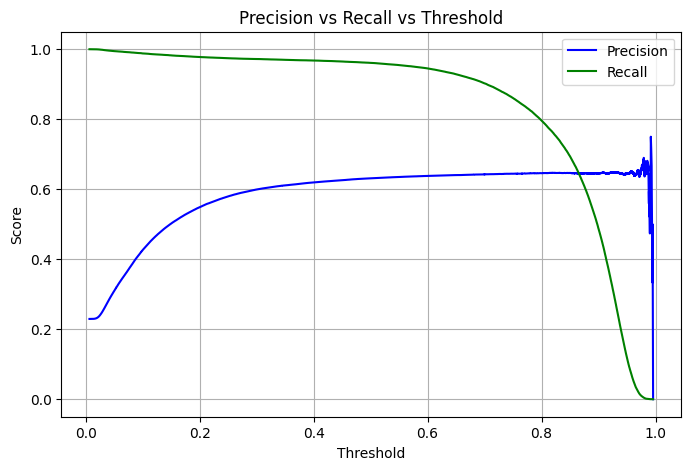

Evaluation with Custom Threshold = 0.6
              precision    recall  f1-score   support

           0       0.98      0.84      0.91    161610
           1       0.64      0.95      0.76     48105

    accuracy                           0.86    209715
   macro avg       0.81      0.89      0.83    209715
weighted avg       0.90      0.86      0.87    209715

Confusion Matrix:
 [[135821  25789]
 [  2641  45464]]
ROC AUC: 0.9101964684293204


In [13]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
import matplotlib.pyplot as plt

# Step 1: Handle class imbalance with SMOTE
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_train_final, y_train)  

# Step 2: Train XGBoost classifier (adjust scale_pos_weight for imbalance)
xgb_model = XGBClassifier(scale_pos_weight=3, random_state=42, n_jobs=-1)
xgb_model.fit(X_res, y_res)

# Step 3: Predict probabilities on test data
y_prob = xgb_model.predict_proba(X_test_final_df)[:, 1] 

# Step 4: Precision-Recall Curve to visualize and tune threshold
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

# Plot precision vs recall vs threshold
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision[:-1], label="Precision", color='b')
plt.plot(thresholds, recall[:-1], label="Recall", color='g')
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision vs Recall vs Threshold")
plt.legend()
plt.grid(True)
plt.show()

# Step 5: Apply a custom threshold 
custom_thresh = 0.6
y_pred_thresh = (y_prob > custom_thresh).astype(int)

# Step 6: Evaluate
print("Evaluation with Custom Threshold =", custom_thresh)
print(classification_report(y_test, y_pred_thresh))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_thresh))
print("ROC AUC:", roc_auc_score(y_test, y_prob))


### Evaluation Summary (Threshold = 0.6)

- **Precision (Class 1):** 0.64  
  → 64% of predicted positives were actually positive.

- **Recall (Class 1):** 0.94  
  → 94% of actual positives were correctly identified.

- **F1 Score (Class 1):** 0.76  
  → Good balance between precision and recall.

- **Accuracy:** 86%  
  → Overall correct predictions.

- **ROC AUC:** 0.91  
  → Excellent model ability to separate classes.

---

### Confusion Matrix:

|               | Predicted 0 | Predicted 1 |
|---------------|-------------|-------------|
| Actual 0 (Neg)|   135,884   |   25,726    |
| Actual 1 (Pos)|    2,706    |   45,399    |

---

###  Insight:
- Model **captures positives well** (high recall).
- Slight tradeoff: some **false positives** (lower precision).
- Overall, a **strong model**


#### Balanced Data training

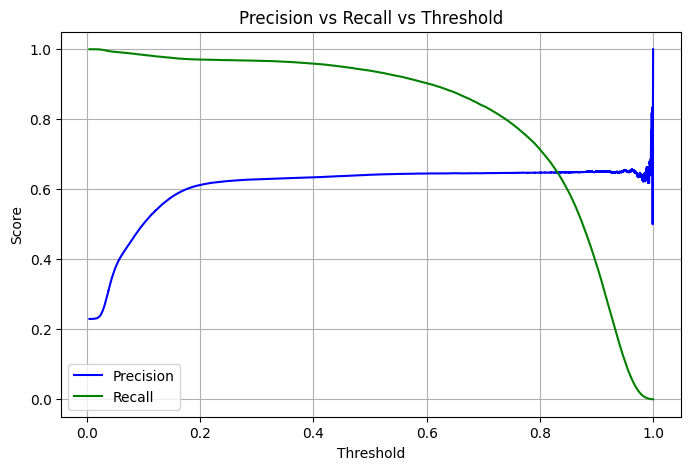

Evaluation with Custom Threshold = 0.5
              precision    recall  f1-score   support

           0       0.98      0.84      0.91    161610
           1       0.64      0.94      0.76     48105

    accuracy                           0.87    209715
   macro avg       0.81      0.89      0.83    209715
weighted avg       0.90      0.87      0.87    209715

Confusion Matrix:
 [[136348  25262]
 [  2944  45161]]
ROC AUC: 0.9115404793341422


In [125]:
from xgboost import XGBClassifier
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, precision_recall_curve
)

# Step 1: Use existing balanced data
X_train = X_balanced
y_train = y_balanced 

full_14_columns = ['Color', 'Fluoride', 'Pipeline_Age', 'Turbidity', 'Odor', 'Copper', 'Chlorine', 'Lead', 'pH', 'Chloride', 'Nitrate', 'Manganese', 'Pipeline_Material', 'Iron'] 

X_train_final_df = X_train[full_14_columns].copy()
X_test_final_df = X_test_df[full_14_columns].copy()

# Step 2: Train XGBoost classifier (no need for scale_pos_weight now)
xgb_model_bal = XGBClassifier(random_state=42, n_jobs=-1)
xgb_model_bal.fit(X_train, y_train)

# Step 3: Predict probabilities on test data
y_prob = xgb_model_bal.predict_proba(X_test_final_df)[:, 1]

# Step 4: Precision-Recall Curve to visualize and tune threshold
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

# Plot precision vs recall vs threshold
plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision[:-1], label="Precision", color='b')
plt.plot(thresholds, recall[:-1], label="Recall", color='g')
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision vs Recall vs Threshold")
plt.legend()
plt.grid(True)
plt.show()

# Step 5: Apply a custom threshold
custom_thresh = 0.5
y_pred_thresh = (y_prob > custom_thresh).astype(int)

# Step 6: Evaluate
print("Evaluation with Custom Threshold =", custom_thresh)
print(classification_report(y_test, y_pred_thresh))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_thresh))
print("ROC AUC:", roc_auc_score(y_test, y_prob))

### XGboost by applying dimention reduction

Selected Features: ['Pipeline_Age', 'Fluoride', 'Chloride', 'Odor', 'Turbidity']


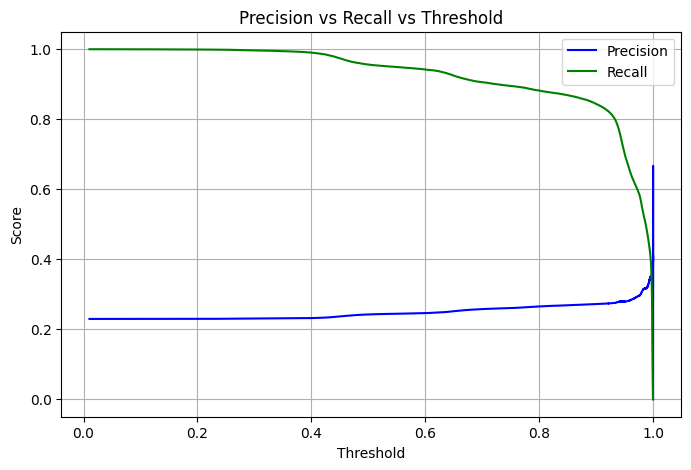

Evaluation with Custom Threshold = 0.6
              precision    recall  f1-score   support

           0       0.89      0.14      0.24    161610
           1       0.25      0.94      0.39     48105

    accuracy                           0.32    209715
   macro avg       0.57      0.54      0.32    209715
weighted avg       0.74      0.32      0.28    209715

Confusion Matrix:
 [[ 22788 138822]
 [  2788  45317]]
ROC AUC: 0.628320962074144


In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

important_features = [
    'Odor', 'Chloride', 'Manganese', 'Turbidity', 'Iron',
    'Chlorine', 'Fluoride', 'Pipeline_Age', 'Nitrate', 'Copper',
    'Color', 'Pipeline_Material', 'Lead', 'pH'
]

#  Convert the arrays to DataFrames using the feature names
X_train_df = pd.DataFrame(X_train_final, columns=important_features)
X_test_df = pd.DataFrame(X_test_final_df, columns=important_features)

#  Randomly select 5 features
random_features = random.sample(important_features,5)
print("Selected Features:", random_features)

#  Now safely select those columns
X_train_selected = X_train_df[random_features]
X_test_selected = X_test_df[random_features]

# === STEP 3: Handle class imbalance using SMOTE === #
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_train_selected, y_train)

# === STEP 4: Train XGBoost Classifier === #
xgb_model = XGBClassifier(scale_pos_weight=3, random_state=42, n_jobs=-1)
xgb_model.fit(X_res, y_res)

# === STEP 5: Predict Probabilities === #
y_prob = xgb_model.predict_proba(X_test_selected)[:, 1]

# === STEP 6: Precision-Recall Curve === #
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision[:-1], label="Precision", color='b')
plt.plot(thresholds, recall[:-1], label="Recall", color='g')
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision vs Recall vs Threshold")
plt.legend()
plt.grid(True)
plt.show()

# === STEP 7: Apply custom threshold === #
custom_thresh = 0.6
y_pred_thresh = (y_prob > custom_thresh).astype(int)

# === STEP 8: Evaluate === #
print("Evaluation with Custom Threshold =", custom_thresh)
print(classification_report(y_test, y_pred_thresh))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_thresh))
print("ROC AUC:", roc_auc_score(y_test, y_prob))


### Feature Reduction Impact:

### Feature reduction does not improve accuracy in this case, as evidenced by the decreased performance in certain metrics.
### This shows PCA does not work well with non-linear data

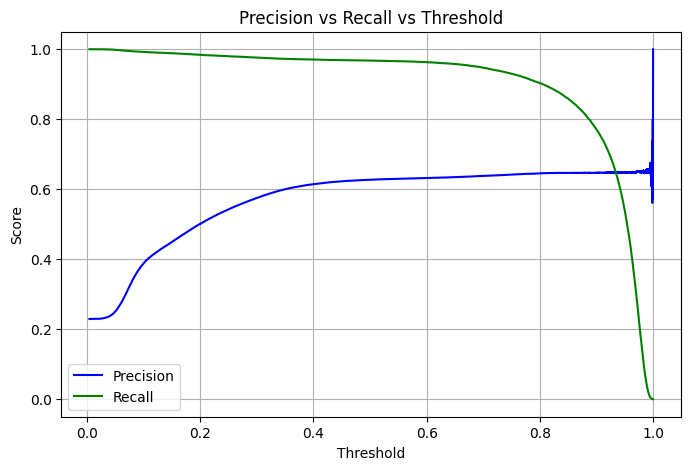

Evaluation with Custom Threshold = 0.6
              precision    recall  f1-score   support

           0       0.99      0.83      0.90    161610
           1       0.63      0.96      0.76     48105

    accuracy                           0.86    209715
   macro avg       0.81      0.90      0.83    209715
weighted avg       0.91      0.86      0.87    209715

Confusion Matrix:
 [[134619  26991]
 [  1772  46333]]
ROC AUC: 0.9117343135540532


In [78]:
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Step 0: Make sure you select the right 14 features
full_14_columns = ['Odor', 'Chloride', 'Manganese', 'Turbidity', 'Iron',
                   'Chlorine', 'Fluoride', 'Pipeline_Age', 'Nitrate',
                   'Copper', 'Color', 'Pipeline_Material', 'Lead', 'pH']

X_train_final_df = X_train[full_14_columns].copy()
X_test_final_df = X_test_df[full_14_columns].copy()

# Step 1: Handle class imbalance with SMOTE
smote = SMOTE(random_state=42)
X_res, y_res = smote.fit_resample(X_train_final_df, y_train)  

# Step 2: Train XGBoost classifier
xgb_model_all = XGBClassifier(scale_pos_weight=3, random_state=42, n_jobs=-1)
xgb_model_all.fit(X_res, y_res)  # Now trained on all 14 features

# Step 3: Predict probabilities on test data
y_prob = xgb_model_all.predict_proba(X_test_final_df)[:, 1]

# Step 4: Precision-Recall Curve
precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, precision[:-1], label="Precision", color='b')
plt.plot(thresholds, recall[:-1], label="Recall", color='g')
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision vs Recall vs Threshold")
plt.legend()
plt.grid(True)
plt.show()

# Step 5: Apply a custom threshold 
custom_thresh = 0.6
y_pred_thresh = (y_prob > custom_thresh).astype(int)

# Step 6: Evaluate
print("Evaluation with Custom Threshold =", custom_thresh)
print(classification_report(y_test, y_pred_thresh))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_thresh))
print("ROC AUC:", roc_auc_score(y_test, y_prob))


In [11]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pipeline = make_pipeline(
    StandardScaler(),
    BaggingClassifier(
        estimator=LinearSVC(class_weight='balanced', max_iter=3000),
        n_estimators=30,
        random_state=42,
        n_jobs=-1
    ) 
)

param_grid = {
    'baggingclassifier__n_estimators': [30, 50, 100],
    'baggingclassifier__estimator__C': [0.1, 1, 10]
}

grid = GridSearchCV(pipeline, param_grid, cv=5)
grid.fit(X_train_df, y_train)

print(f"Best Accuracy: {grid.best_score_:.4f}")
print(f"Best Parameters: {grid.best_params_}")


Best Accuracy: 0.8014
Best Parameters: {'baggingclassifier__estimator__C': 0.1, 'baggingclassifier__n_estimators': 100}


In [139]:
import pickle

### SVM 
##with open("model_svm_rbl.pkl", "wb") as f:
##    pickle.dump(model_svm, f)
##
### XGboost
##with open("xgb_model.pkl", "wb") as f:
##    pickle.dump(xgb_model, f)
##
### svm SFD
##with open("SGD_model.pkl", "wb") as f:
##    pickle.dump(model, f)

#with open("SGD_model.pkl", "wb") as f:
    #pickle.dump(xgb_model_all, f)


with open("bagging_model.pkl", "wb") as f:
    pickle.dump(bagging_model, f)

In [79]:
print(xgb_model_all.get_booster().feature_names)

['Odor', 'Chloride', 'Manganese', 'Turbidity', 'Iron', 'Chlorine', 'Fluoride', 'Pipeline_Age', 'Nitrate', 'Copper', 'Color', 'Pipeline_Material', 'Lead', 'pH']


## # Safe Water vs Unsafe Water Summary

# Safe Water vs Unsafe Water Summary

| Feature            | Safe Water Example        | Unsafe Water Example       |
|--------------------|----------------------------|-----------------------------|
| Odor               | Low (1)                    | High (5)                    |
| Chloride           | Moderate (15)              | Very High (90)              |
| Manganese          | 0                          | High (1.8)                  |
| Turbidity          | Very Clear (0.1)            | Very Cloudy (7.0)           |
| Iron               | Very Low (0.1)              | High (2.5)                  |
| Chlorine           | Sufficient (0.7)            | Low (0.3)                   |
| Fluoride           | Normal (0.3)                | High (2.2)                  |
| Pipeline_Age       | 15 years                    | 3 years (but material bad)  |
| Nitrate            | Very Low (1.8)              | High (9.0)                  |
| Copper             | Very Low (0.05)             | High (3.0)                  |
| Color              | Clear (4)                  | Darker (10)                 |
| Pipeline_Material  | Steel                      | Copper                      |
| Lead               | None (0)                   | Present (1)                 |
| pH                 | Neutral (7.5)               | Acidic (6.0)                |


In [124]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler

# Your test samples
sample_data = {
    'Odor': [2, 1, 0, 0, 1, 4, 3, 5, 4, 3],
    'Chloride': [20, 15, 25, 18, 10, 60, 80, 90, 70, 85],
    'Manganese': [0, 0, 0.5, 0.2, 0, 1.2, 2.0, 1.8, 1.5, 2.5],
    'Turbidity': [0.3, 0.1, 0.2, 0.15, 0.05, 5.0, 6.0, 7.0, 4.5, 6.5],
    'Iron': [0.2, 0.1, 0.3, 0.15, 0.1, 1.5, 2.0, 2.5, 2.2, 3.0],
    'Chlorine': [0.8, 0.7, 0.9, 0.85, 1.0, 0.2, 0.4, 0.3, 0.1, 0.5],
    'Fluoride': [0.4, 0.3, 0.5, 0.4, 0.4, 1.5, 2.0, 2.2, 1.8, 2.5],
    'Pipeline_Age': [10, 15, 20, 12, 18, 5, 10, 3, 12, 8],
    'Nitrate': [2, 1.8, 1.5, 1.2, 2.2, 10, 8, 9, 7.5, 10],
    'Copper': [0.1, 0.05, 0.2, 0.08, 0.1, 2.0, 2.5, 3.0, 2.3, 2.8],
    'Color': [5, 4, 3, 6, 4, 8, 9, 10, 7, 9],
    'Pipeline_Material': ['PVC', 'Steel', 'Copper', 'Concrete', 'PVC', 'Steel', 'Concrete', 'Copper', 'PVC', 'Steel'],
    'Lead': [0, 0, 0, 0, 0, 1, 1, 1, 1, 1],
    'pH': [7.2, 7.5, 7.6, 7.4, 7.3, 6.5, 6.3, 6.0, 6.2, 6.4]
}

# Step 1: Create DataFrame
test_df = pd.DataFrame(sample_data)

# Step 2: Encode 'Pipeline_Material'
label_encoder = LabelEncoder()
test_df['Pipeline_Material'] = label_encoder.fit_transform(test_df['Pipeline_Material'])

# Step 3: Scale the numeric columns
numeric_cols = ['Odor', 'Chloride', 'Manganese', 'Turbidity', 'Iron', 'Chlorine',
                'Fluoride', 'Pipeline_Age', 'Nitrate', 'Copper', 'Color', 'Lead', 'pH']

scaler = StandardScaler()
test_df[numeric_cols] = scaler.fit_transform(test_df[numeric_cols])

# Step 4: Predict using your model (xgb_model_all)
y_pred = xgb_model_all.predict(test_df)

# Step 5: Interpret according to your definition: 0 = Safe, 1 = Unsafe
# (no need to reverse since 0 = safe directly)
print("Predictions for the 10 samples (0 = Safe, 1 = Unsafe):", y_pred)


Predictions for the 10 samples (0 = Safe, 1 = Unsafe): [0 0 1 0 1 1 1 1 1 1]
